<a href="https://colab.research.google.com/github/SriVarshiniD/NIE-ML2/blob/main/ML2Lab10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset Shape: (569, 30)

First 5 rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst 

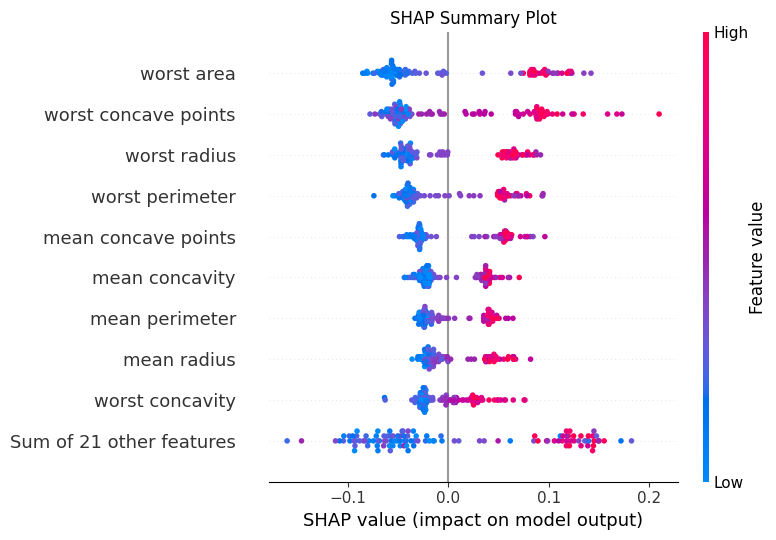


Top 10 Important Features:
                 Feature  Importance
23            worst area    0.066893
27  worst concave points    0.063026
20          worst radius    0.048655
22       worst perimeter    0.045389
7    mean concave points    0.041439
6         mean concavity    0.029439
2         mean perimeter    0.027883
0            mean radius    0.026630
26       worst concavity    0.024727
3              mean area    0.023054


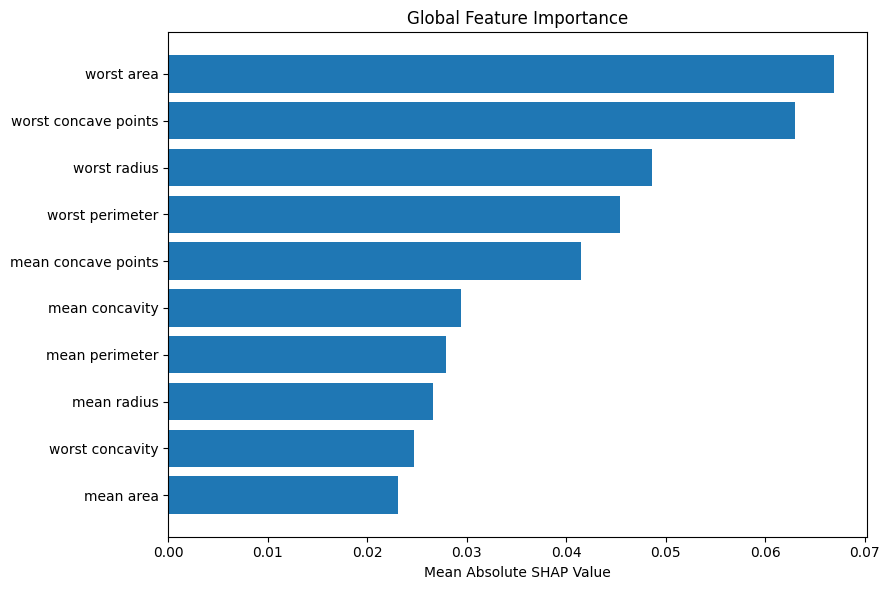


INSTANCE 1
Actual: malignant
Predicted: malignant


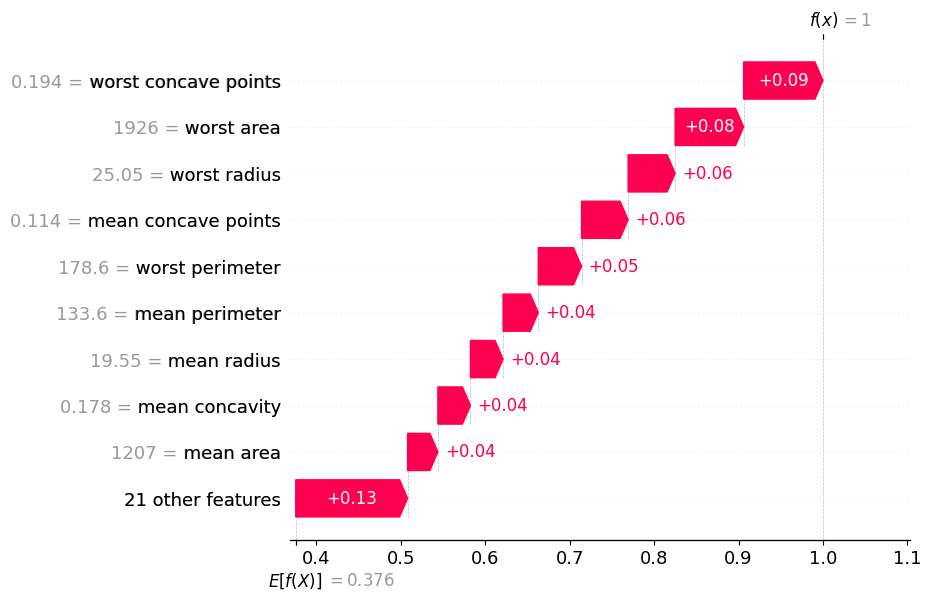


INSTANCE 2
Actual: benign
Predicted: benign


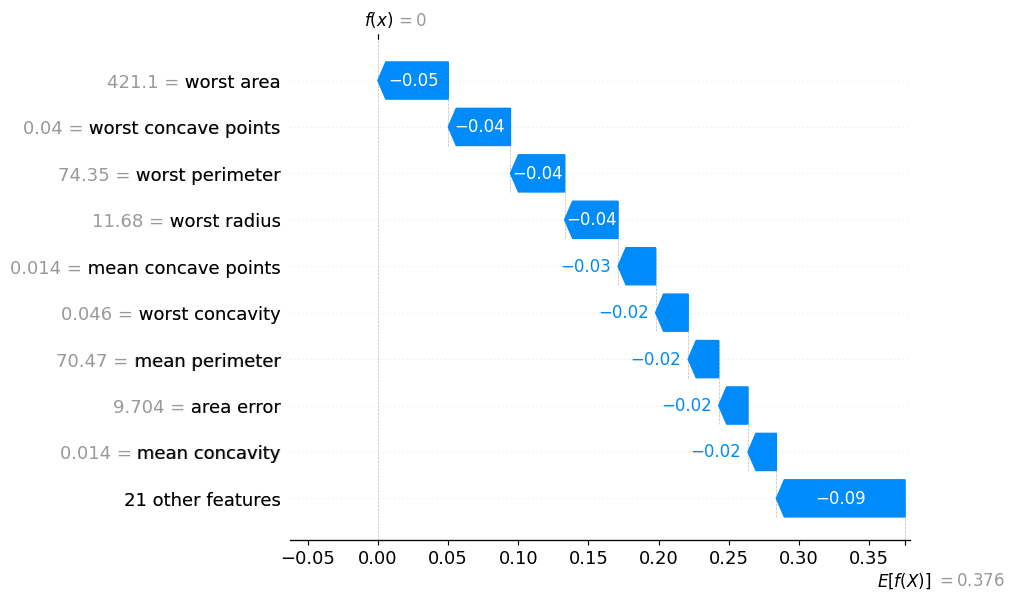


Explainable AI Analysis Completed!
Model Accuracy: 95.61 %

Top 5 Features:
                 Feature  Importance
23            worst area    0.066893
27  worst concave points    0.063026
20          worst radius    0.048655
22       worst perimeter    0.045389
7    mean concave points    0.041439


In [ ]:

# PROGRAM 10: EXPLAINABLE AI USING SHAP

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# --------------------------------
# 1. LOAD DATASET
# --------------------------------

data = load_breast_cancer()

X = pd.DataFrame(
    data.data,
    columns=data.feature_names
)

y = data.target

print("Dataset Shape:", X.shape)

print("\nFirst 5 rows:")
print(X.head())

# --------------------------------
# 2. SPLIT DATASET
# --------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# --------------------------------
# 3. TRAIN RANDOM FOREST MODEL
# --------------------------------

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

# --------------------------------
# 4. MODEL EVALUATION
# --------------------------------

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=data.target_names
    )
)

# --------------------------------
# 5. APPLY SHAP
# --------------------------------

explainer = shap.TreeExplainer(model)

# Explain at least 2 test instances
X_instances = X_test.iloc[:2]

shap_values = explainer(X_instances)

# Select explanation for malignant class
# Class 0 = malignant
malignant_explanation = shap_values[:, :, 0]

# --------------------------------
# 6. SHAP SUMMARY PLOT
# --------------------------------

# Explain the complete test dataset
all_shap_values = explainer(X_test)

malignant_all = all_shap_values[:, :, 0]

plt.figure(figsize=(10, 6))

shap.plots.beeswarm(
    malignant_all,
    max_display=10,
    show=False
)

plt.title("SHAP Summary Plot")

plt.tight_layout()
plt.show()

# --------------------------------
# 7. SHAP FEATURE IMPORTANCE
# --------------------------------

shap_importance = np.abs(
    malignant_all.values
).mean(axis=0)

importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': shap_importance
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

print("\nTop 10 Important Features:")
print(importance_df.head(10))

# Plot feature importance
plt.figure(figsize=(9, 6))

plt.barh(
    importance_df['Feature'].head(10)[::-1],
    importance_df['Importance'].head(10)[::-1]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.title("Global Feature Importance")

plt.tight_layout()
plt.show()

# --------------------------------
# 8. WATERFALL PLOT - INSTANCE 1
# --------------------------------

print("\nINSTANCE 1")

prediction1 = model.predict(X_instances.iloc[[0]])[0]

print("Actual:", data.target_names[y_test[0]])
print("Predicted:", data.target_names[prediction1])

shap.plots.waterfall(
    malignant_explanation[0],
    max_display=10
)

# --------------------------------
# 9. WATERFALL PLOT - INSTANCE 2
# --------------------------------

print("\nINSTANCE 2")

prediction2 = model.predict(X_instances.iloc[[1]])[0]

print("Actual:", data.target_names[y_test[1]])
print("Predicted:", data.target_names[prediction2])

shap.plots.waterfall(
    malignant_explanation[1],
    max_display=10
)

# --------------------------------
# 10. FINAL RESULT
# --------------------------------

print("\nExplainable AI Analysis Completed!")

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nTop 5 Features:")
print(importance_df.head(5))
